Петров Александр М26-555

# Домашнее задание. Применение статистических критериев

В этом задании вы потренируетесь подбирать и применять статистические критерии под конкретную задачу: доверительные интервалы, одновыборочные и двухвыборочные тесты, дисперсионный анализ и анализ долей.

Инструкции:
- Скопируйте ноутбук себе и заполните ячейки с кодом и выводами.
- В каждой задаче приведите код, выведите на экран требуемые значения и добавьте краткий вывод (1-2 фразы) в текстовой ячейке.
- Там, где используется случайная генерация, фиксируйте np.random.seed для воспроизводимости.
- Разрешённые библиотеки: numpy, scipy, statsmodels, matplotlib.

Формат сдачи: файл .ipynb с заполненными ячейками. Перед отправкой перезапустите ноутбук от начала до конца, чтобы **вывод от кода был отображён**.

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.proportion import proportion_confint, proportions_ztest


### Задание 1. Сопоставление статистик

Для каждой ситуации укажите наиболее подходящий критерий из списка: z-тест, t-тест (объединённый), Welch t-тест, F-тест (сравнение дисперсий), критерий хи-квадрат (согласия), однофакторный ANOVA, Tukey HSD, критерий Левена.

**Ситуации:**
1. Нужно проверить, отличается ли средний объём дозы от заданного значения; дисперсия процесса известна.
2. Сравнить средние двух независимых групп при неизвестных, но равных дисперсиях.
3. Сравнить средние двух независимых групп при неизвестных и неравных дисперсиях.
4. Оценить, одинаковы ли средние в трёх и более группах.
5. Проверить, согласуются ли наблюдаемые частоты с распределением Пуассона.

**Что сделать:** для каждой ситуации кратко (1-2 предложения) обоснуйте выбор критерия в MarkDown-ячейке ниже.

**Вывод:**

1. **z-тест:** Стандартное отклонение генеральной совокупности известно, поэтому для проверки гипотезы о среднем относительно заданного значения используем z-статистику
2. **Объединённый t-тест Стьюдента:** Сравниваются две независимые группы, дисперсии неизвестны, но предполагаются равными, поэтому используем pooled t-test
3. **Welch t-тест:** Для двух независимых групп с неизвестными и потенциально неравными дисперсиями подходит t-тест Уэлча, так как он не требует предположения о равенстве дисперсий
4. **Однофакторный ANOVA:** Для сравнения средних трёх и более независимых групп сначала используем однофакторный дисперсионный анализ. Если он выявит различия, для поиска конкретных пар применяем Tukey HSD
5. **Критерий хи-квадрат согласия:** Сравниваем наблюдаемые частоты с ожидаемыми частотами теоретического распределения Пуассона


### Задание 2. Тест для дозатора

Дозатор настроен на среднюю дозу 3.00 г. Получено $n = 50$ измерений со средним $\bar X = 3.005$ и известным стандартным отклонением процесса $\sigma = 0.015$.

**Что сделать:**
- проверьте гипотезу $H_0: \mu = 3.00$ при $\alpha = 0.05$;
- постройте 95% доверительный интервал для $\mu$;
- сделайте практический вывод в MarkDown-ячейке: нужно ли перенастраивать дозатор.

**Выведите на экран:** наблюдаемое значение статистики, p-value, границы доверительного интервала.

In [26]:
mu0, xbar, sigma, n = 3.00, 3.005, 0.015, 50
alpha = 0.05

# H0: mu = mu0; H1: mu != mu0
z_stat = (xbar - mu0) / (sigma / np.sqrt(n))
p_value = 2 * stats.norm.sf(abs(z_stat))

# 95%-й доверительный интервал при известном sigma
z_critical = stats.norm.ppf(1 - alpha / 2)
ci_low = xbar - z_critical * sigma / np.sqrt(n)
ci_high = xbar + z_critical * sigma / np.sqrt(n)

print(f"z-статистика: {z_stat:.4f}")
print(f"p-value: {p_value:.6f}")
print(f"95%-й доверительный интервал: [{ci_low:.6f}; {ci_high:.6f}] г")
print(f"Уровень значимости alpha: {alpha:.2f}")


z-статистика: 2.3570
p-value: 0.018422
95%-й доверительный интервал: [3.000842; 3.009158] г
Уровень значимости alpha: 0.05


**Вывод:** p-value = 0.0184 меньше 0.05, поэтому нулевая гипотеза о среднем объёме 3.00 г отвергается. 95%-й доверительный интервал [3.00084; 3.00916] г целиком выше целевого значения: средняя доза статистически значимо завышена примерно на 0.005 г, поэтому дозатор следует перенастроить, если заданная точность 3.00 г должна соблюдаться. Допустимый технологический допуск при практическом решении также нужно учитывать


### Задание 3. Сравнение прочности материалов

Даны две независимые выборки прочности материалов (в MPa):

A (n=15): 51.99, 49.45, 52.59, 56.09, 49.06, 49.06, 56.32, 53.07, 48.12, 52.17, 48.15, 48.14, 50.97, 42.35, 43.10

B (n=10): 48.63, 45.92, 53.89, 46.55, 43.53, 60.79, 50.65, 52.41, 43.45, 48.73

**Что сделать:**
- проверьте равенство дисперсий (критерий Левена и классический F-тест);
- в зависимости от результата примените объединённый t-тест или Welch t-тест для проверки $H_0: \mu_A = \mu_B$ при $\alpha = 0.05$;
- постройте 95% доверительный интервал для разности средних и интерпретируйте его.

Выведите на экран: p-value критерия Левена, F-статистику и p-value F-теста, статистику и p-value выбранного t-теста, разность средних и границы доверительного интервала.

In [27]:
A = np.array([51.99,49.45,52.59,56.09,49.06,49.06,56.32,53.07,48.12,52.17,48.15,48.14,50.97,42.35,43.10])
B = np.array([48.63,45.92,53.89,46.55,43.53,60.79,50.65,52.41,43.45,48.73])

alpha = 0.05
n_A, n_B = len(A), len(B)
mean_A, mean_B = np.mean(A), np.mean(B)
var_A, var_B = np.var(A, ddof=1), np.var(B, ddof=1)
mean_diff = mean_A - mean_B

# 1. Проверка равенства дисперсий критерием Левена
levene_stat, levene_p = stats.levene(A, B, center='median')

# 2. Классический двусторонний F-тест для отношения дисперсий
f_stat = var_A / var_B
df1, df2 = n_A - 1, n_B - 1
f_p = 2 * min(stats.f.cdf(f_stat, df1, df2), stats.f.sf(f_stat, df1, df2))
f_p = min(f_p, 1.0)

# 3. Выбор t-теста: при отсутствии свидетельств о разных дисперсиях
# используем объединённый t-тест, иначе — тест Уэлча.
equal_variances = (levene_p > alpha) and (f_p > alpha)
if equal_variances:
    test_name = "объединённый t-тест Стьюдента"
    pooled_var = ((n_A - 1) * var_A + (n_B - 1) * var_B) / (n_A + n_B - 2)
    standard_error = np.sqrt(pooled_var * (1 / n_A + 1 / n_B))
    df_t = n_A + n_B - 2
else:
    test_name = "Welch t-тест"
    term_A = var_A / n_A
    term_B = var_B / n_B
    standard_error = np.sqrt(term_A + term_B)
    df_t = (term_A + term_B) ** 2 / (term_A ** 2 / (n_A - 1) + term_B ** 2 / (n_B - 1))

# Статистика и p-value выбранного двухстороннего t-теста
t_stat = mean_diff / standard_error
t_p_value = 2 * stats.t.sf(abs(t_stat), df_t)

# 95%-й доверительный интервал для разности средних A - B
t_critical = stats.t.ppf(1 - alpha / 2, df_t)
ci_low = mean_diff - t_critical * standard_error
ci_high = mean_diff + t_critical * standard_error

print(f"Среднее A: {mean_A:.4f}; среднее B: {mean_B:.4f}")
print(f"Выборочная дисперсия A: {var_A:.4f}; дисперсия B: {var_B:.4f}")
print(f"Критерий Левена: statistic = {levene_stat:.4f}, p-value = {levene_p:.6f}")
print(f"F-тест: F = {f_stat:.4f}, df = ({df1}, {df2}), p-value = {f_p:.6f}")
print(f"Выбранный тест: {test_name}")
print(f"t-статистика: {t_stat:.4f}; число степеней свободы: {df_t:.3f}; p-value = {t_p_value:.6f}")
print(f"Разность средних A - B: {mean_diff:.4f} MPa")
print(f"95%-й доверительный интервал для A - B: [{ci_low:.4f}; {ci_high:.4f}] MPa")


Среднее A: 50.0420; среднее B: 49.4550
Выборочная дисперсия A: 15.8118; дисперсия B: 27.9576
Критерий Левена: statistic = 0.4676, p-value = 0.500926
F-тест: F = 0.5656, df = (14, 9), p-value = 0.327105
Выбранный тест: объединённый t-тест Стьюдента
t-статистика: 0.3171; число степеней свободы: 23.000; p-value = 0.754051
Разность средних A - B: 0.5870 MPa
95%-й доверительный интервал для A - B: [-3.2428; 4.4168] MPa


**Вывод:** критерий Левена (p = 0.5009) и F-тест (p = 0.3271) не выявили статистически значимого различия дисперсий на уровне 0.05, поэтому мы выбираем объединённый t-тест Стьюдента. Его p-value = 0.7541, а 95%-й доверительный интервал разности средних A − B равен [−3.24; 4.42] MPa и содержит ноль: статистически значимых различий средней прочности материалов нет


### Задание 4. До и после: уровень глюкозы

Клиническое исследование: у 10 пациентов измерен уровень глюкозы (ммоль/л) до и после приёма нового лекарства.

До: 7.1, 6.8, 7.5, 6.9, 7.3, 6.5, 7.0, 6.7, 7.2, 6.9

После: 6.6, 6.4, 7.1, 6.5, 7.2, 6.3, 6.6, 6.4, 7.0, 6.4

**Что сделать:**
- проверьте нормальность распределения разностей (критерий Шапиро-Уилка);
- в зависимости от результатов проверки на нормальность примените либо парный t-тест при $\alpha = 0.01$, либо критерий Уилкоксона (**только один**, необходимо выбрать и обосновать решение);
- сделайте практический вывод: достоверно ли снижается уровень глюкозы.

**Выведите на экран:** p-value критерия Шапиро-Уилка, статистику и p-value выбранного теста, среднюю разность.

In [28]:
before = np.array([7.1,6.8,7.5,6.9,7.3,6.5,7.0,6.7,7.2,6.9])
after  = np.array([6.6,6.4,7.1,6.5,7.2,6.3,6.6,6.4,7.0,6.4])
diff = after - before

alpha_test = 0.01
alpha_normality = 0.05

# Проверяем нормальность парных разностей
shapiro_stat, shapiro_p = stats.shapiro(diff)

# Выбираем один тест в зависимости от результата проверки нормальности
# Направленная альтернатива: уровень до лечения выше, чем после
if shapiro_p > alpha_normality:
    selected_test = "парный t-тест"
    test_result = stats.ttest_rel(before, after, alternative='greater')
else:
    selected_test = "критерий Уилкоксона для связанных выборок"
    test_result = stats.wilcoxon(before, after, alternative='greater')

mean_diff_after_before = np.mean(diff)
mean_reduction = np.mean(before - after)

print(f"Шапиро — Уилк: W = {shapiro_stat:.4f}, p-value = {shapiro_p:.6f}")
print(f"Выбранный тест: {selected_test}")
print(f"Статистика теста: {test_result.statistic:.4f}")
print(f"p-value теста: {test_result.pvalue:.8f}")
print(f"Средняя разность (после - до): {mean_diff_after_before:.4f} ммоль/л")
print(f"Среднее снижение (до - после): {mean_reduction:.4f} ммоль/л")
print(f"Уровень значимости для проверки эффекта: alpha = {alpha_test:.2f}")


Шапиро — Уилк: W = 0.8960, p-value = 0.197745
Выбранный тест: парный t-тест
Статистика теста: 7.9649
p-value теста: 0.00001146
Средняя разность (после - до): -0.3400 ммоль/л
Среднее снижение (до - после): 0.3400 ммоль/л
Уровень значимости для проверки эффекта: alpha = 0.01


**Вывод:** p-value критерия Шапиро - Уилка = 0.1977 больше 0.05, поэтому нет оснований отвергать нормальность разностей; применён парный t-тест с направленной альтернативой «до > после». p-value = 0.0000115 меньше 0.01, среднее снижение составляет 0.34 ммоль/л: в этой выборке есть статистически значимые свидетельства снижения уровня глюкозы после приёма лекарства


### Задание 5. ANOVA на реальных данных

Данные эксперимента по влиянию четырёх типов корма на массу животных (в граммах), по 6 наблюдений в группе:

A: 251, 262, 248, 255, 260, 257
B: 263, 270, 265, 272, 260, 266
C: 268, 275, 271, 280, 277, 269
D: 282, 290, 285, 295, 288, 293

**Что сделать:**
- постройте визуализацию (ящики с усами и точки);
- проверьте нормальность по группам (Шапиро-Уилк) и равенство дисперсий (критерий Левена);
- проведите однофакторный ANOVA;
- при значимом результате выполните попарные сравнения Tukey HSD и определите наиболее эффективный корм.

**Выведите на экран:** p-value Шапиро-Уилка по каждой группе, p-value критерия Левена, F-статистику и p-value ANOVA, таблицу Tukey HSD.

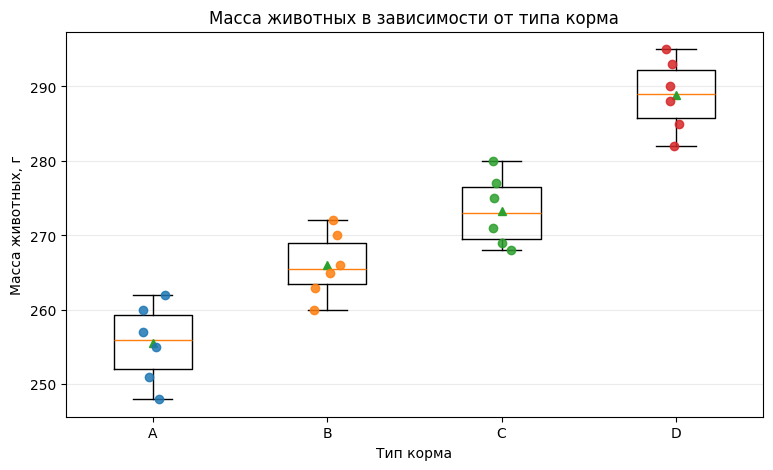

Группа A: W = 0.9682, p-value = 0.879904
Группа B: W = 0.9738, p-value = 0.916850
Группа C: W = 0.9387, p-value = 0.648751
Группа D: W = 0.9781, p-value = 0.941526

Критерий Левена: statistic = 0.1291, p-value = 0.941694
ANOVA: F = 49.9246, p-value = 0.0000000018

Результаты Tukey HSD:
Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
     A      B     10.5 0.0064  2.6524 18.3476   True
     A      C  17.8333    0.0  9.9858 25.6809   True
     A      D  33.3333    0.0 25.4858 41.1809   True
     B      C   7.3333 0.0723 -0.5142 15.1809  False
     B      D  22.8333    0.0 14.9858 30.6809   True
     C      D     15.5 0.0001  7.6524 23.3476   True
----------------------------------------------------

Средние значения по группам:
Корм A: 255.50 г
Корм B: 266.00 г
Корм C: 273.33 г
Корм D: 288.83 г
Наибольшая средняя масса — у корма D: 288.83 г


In [29]:
A = [251, 262, 248, 255, 260, 257]
B = [263, 270, 265, 272, 260, 266]
C = [268, 275, 271, 280, 277, 269]
D = [282, 290, 285, 295, 288, 293]

groups = {"A": np.array(A), "B": np.array(B), "C": np.array(C), "D": np.array(D)}
group_names = list(groups.keys())
group_data = [groups[name] for name in group_names]

# 1. Визуализация: boxplot и индивидуальные наблюдения
np.random.seed(42)
fig, ax = plt.subplots(figsize=(9, 5))
ax.boxplot(group_data, showmeans=True)
for position, (name, values) in enumerate(groups.items(), start=1):
    jitter = np.random.uniform(-0.08, 0.08, size=len(values))
    ax.scatter(position + jitter, values, alpha=0.85, zorder=3, label=f"Корм {name}")
ax.set_xticks(range(1, len(group_names) + 1), group_names)
ax.set_xlabel("Тип корма")
ax.set_ylabel("Масса животных, г")
ax.set_title("Масса животных в зависимости от типа корма")
ax.grid(axis="y", alpha=0.25)
plt.show()

# 2. Проверка нормальности в каждой группе с помощью Шапиро — Уилка
shapiro_results = {}
for name, values in groups.items():
    result = stats.shapiro(values)
    shapiro_results[name] = result
    print(f"Группа {name}: W = {result.statistic:.4f}, p-value = {result.pvalue:.6f}")

# 3. Проверка равенства дисперсий критерием Левена
levene_result = stats.levene(*group_data, center='median')
print(f"\nКритерий Левена: statistic = {levene_result.statistic:.4f}, p-value = {levene_result.pvalue:.6f}")

# 4. Однофакторный ANOVA
anova_result = stats.f_oneway(*group_data)
print(f"ANOVA: F = {anova_result.statistic:.4f}, p-value = {anova_result.pvalue:.10f}")

# 5. Если ANOVA значим, проводим post-hoc сравнения Tukey HSD
all_values = np.concatenate(group_data)
all_labels = np.concatenate([[name] * len(values) for name, values in groups.items()])
if anova_result.pvalue < 0.05:
    tukey_result = pairwise_tukeyhsd(endog=all_values, groups=all_labels, alpha=0.05)
    print("\nРезультаты Tukey HSD:")
    print(tukey_result.summary())
else:
    tukey_result = None
    print("ANOVA незначим; post-hoc сравнения не выполняются.")

# Наиболее эффективный корм по максимальной средней массе
means = {name: np.mean(values) for name, values in groups.items()}
best_group = max(means, key=means.get)
print("\nСредние значения по группам:")
for name, value in means.items():
    print(f"Корм {name}: {value:.2f} г")
print(f"Наибольшая средняя масса — у корма {best_group}: {means[best_group]:.2f} г")


**Вывод:** во всех четырёх группах p-value критерия Шапиро — Уилка больше 0.05, а критерий Левена (p = 0.9417) не выявил неоднородности дисперсий; эти проверки не дают оснований отвергать соответствующие допущения ANOVA. Однофакторный ANOVA выявил различия между средними (F = 49.9246, p < 0.001); по Tukey HSD корм D даёт наибольшую среднюю массу (288.83 г) и статистически превосходит A, B и C, поэтому среди проверенных вариантов наиболее эффективен корм D


### Задание 6. A/B-тест по конверсии

Проводится A/B-тест на лендинге. В контрольной группе из 1000 пользователей конверсий 85, в тестовой группе из 1000 пользователей конверсий 120.

**Что сделать:**
- постройте 95% доверительные интервалы Уилсона для конверсии каждой группы;
- проверьте, значимо ли различаются конверсии (критерий хи-квадрат на таблице 2x2 или z-тест для двух долей) при $\alpha = 0.05$;
- постройте бутстрэп-интервал для разности конверсий (тест минус контроль);
- сделайте вывод, стоит ли выкатывать тестовый вариант.

**Выведите на экран:** границы интервалов Уилсона по группам, статистику и p-value выбранного теста, границы бутстрэп-интервала для разности и точечную разность конверсий.

In [30]:
conv_c, n_c = 85, 1000     # контроль
conv_v, n_v = 120, 1000    # тест

alpha = 0.05
p_c = conv_c / n_c
p_v = conv_v / n_v
difference = p_v - p_c

# 1. 95%-е интервалы Уилсона для каждой конверсии
ci_c = proportion_confint(count=conv_c, nobs=n_c, alpha=alpha, method="wilson")
ci_v = proportion_confint(count=conv_v, nobs=n_v, alpha=alpha, method="wilson")

# 2. Двухвыборочный z-тест для долей (двусторонняя альтернатива)
z_stat, p_value = proportions_ztest(
    count=np.array([conv_v, conv_c]),
    nobs=np.array([n_v, n_c]),
    alternative="two-sided"
)

# 3. Percentile bootstrap для разности конверсий (тест - контроль).
# Для бинарных данных число конверсий в bootstrap-выборке имеет
# Binomial(n, p_hat), что эквивалентно повторной выборке с возвращением
# из исходного массива нулей и единиц
np.random.seed(42)
n_bootstrap = 100_000
boot_conv_c = np.random.binomial(n_c, p_c, size=n_bootstrap) / n_c
boot_conv_v = np.random.binomial(n_v, p_v, size=n_bootstrap) / n_v
boot_differences = boot_conv_v - boot_conv_c
bootstrap_ci = np.quantile(boot_differences, [alpha / 2, 1 - alpha / 2])

print(f"Конверсия контроля: {p_c:.4%}")
print(f"95%-й интервал Уилсона для контроля: [{ci_c[0]:.4%}; {ci_c[1]:.4%}]")
print(f"Конверсия теста: {p_v:.4%}")
print(f"95%-й интервал Уилсона для теста: [{ci_v[0]:.4%}; {ci_v[1]:.4%}]")
print(f"z-статистика сравнения долей: {z_stat:.4f}")
print(f"p-value z-теста: {p_value:.6f}")
print(f"Точечная разность (тест - контроль): {difference:.4%} ({difference * 100:.2f} п.п.)")
print(f"95%-й bootstrap-интервал разности: [{bootstrap_ci[0]:.4%}; {bootstrap_ci[1]:.4%}]")


Конверсия контроля: 8.5000%
95%-й интервал Уилсона для контроля: [6.9263%; 10.3913%]
Конверсия теста: 12.0000%
95%-й интервал Уилсона для теста: [10.1299%; 14.1609%]
z-статистика сравнения долей: 2.5803
p-value z-теста: 0.009871
Точечная разность (тест - контроль): 3.5000% (3.50 п.п.)
95%-й bootstrap-интервал разности: [0.9000%; 6.2000%]


**Вывод:** конверсия тестовой версии равна 12.0% против 8.5% в контроле, прирост составляет 3.5 процентного пункта. Двухвыборочный z-тест даёт p-value = 0.0099 < 0.05, а 95%-й bootstrap-интервал разности [0.9 п.п.; 6.2 п.п.] не включает ноль; результат поддерживает выкатку тестового варианта, желательно с обычным мониторингом защитных метрик и бизнес-показателей
